# Notebook 03 — TensorFlow, Keras, and Data Pipelines

**Learning path:** Deep Learning with TensorFlow  
**Level:** Beginner to Intermediate  
**Part:** Part I — Foundations of Deep Learning  
**Notebook version:** 1.0

---

## Chapter Overview

This notebook moves from the mathematical ideas introduced in Notebook 02 to the practical tools used to build deep-learning systems. You will work with TensorFlow tensors, understand shapes and broadcasting, calculate derivatives automatically with `tf.GradientTape`, build models with the Keras APIs, and prepare datasets with `tf.data`.

The practical workflow uses a small synthetic regression dataset. It is intentionally lightweight and does not require downloading external data.

> **Learning principle:** understand the object and its shape, inspect the computation, and only then build a model or data pipeline.

## Notebook Roadmap

| Section | Topic |
|---:|---|
| 1 | Learning objectives and environment setup |
| 2 | TensorFlow tensors, data types, shapes, and dimensions |
| 3 | Tensor creation, variables, indexing, and tensor operations |
| 4 | Broadcasting, reductions, matrix operations, and NumPy interoperability |
| 5 | Automatic differentiation with `tf.GradientTape` |
| 6 | Eager execution and `tf.function` |
| 7 | Preparing a reproducible example dataset |
| 8 | Building models with Sequential, Functional, and subclassing APIs |
| 9 | Building input pipelines with `tf.data` |
| 10 | Training and evaluating a model with a `tf.data` pipeline |
| 11 | Common mistakes, exercises, and further reading |

## Learning Objectives

By the end of this notebook, you should be able to:

1. Create and inspect TensorFlow tensors and variables.
2. Explain tensor rank, shape, data type, and axis.
3. Apply common tensor operations and reason about broadcasting.
4. Convert data between NumPy arrays and TensorFlow tensors.
5. Use `tf.GradientTape` to calculate derivatives and gradients.
6. Distinguish the Sequential API, Functional API, and model subclassing.
7. Build a reproducible input pipeline using `tf.data.Dataset`.
8. Train, validate, and evaluate a small Keras regression model.

## Prerequisites

- Basic Python programming (variables, functions, lists, and imports).
- Basic NumPy array operations.
- Familiarity with vectors, matrices, derivatives, and gradient descent from Notebook 02.

## Important Conventions

- Unless specified otherwise, feature tensors use `float32`.
- A batch of tabular observations is represented as `(batch_size, number_of_features)`.
- A regression target with one value per observation is represented as `(batch_size, 1)`.
- The training, validation, and test sets remain separate throughout the workflow.
- Normalization parameters are estimated from the training set only.

---
# 1. Environment Setup and Reproducibility

## 1.1 Installing the Libraries

Install the packages in the same Python environment used by your Jupyter kernel. The TensorFlow installation guide lists the currently supported Python versions and platform-specific notes.

```bash
python -m pip install --upgrade pip
python -m pip install -r requirements-notebook03.txt
```

For this learning path, use a supported Python version (currently documented as Python 3.10–3.13 for TensorFlow 2.21). Native Windows TensorFlow installation supports CPU execution; NVIDIA GPU support on Windows requires WSL2 for modern TensorFlow releases. Check the official installation page before configuring a GPU environment.

## 1.2 Import Libraries and Inspect the Environment

We use `tf.keras` as the Keras interface exposed by TensorFlow. TensorFlow 2.16 and later use Keras 3 by default unless the environment is explicitly configured otherwise.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Keras version:", getattr(keras, "__version__", "bundled with TensorFlow"))
print("NumPy:", np.__version__)
print("Available devices:", tf.config.list_physical_devices())

Python: 3.11.0
TensorFlow: 2.21.0
Keras version: 3.15.1
NumPy: 2.4.6
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 1.3 Set Random Seeds

Randomness appears in data generation, dataset shuffling, and neural-network weight initialization. Fixing seeds makes experiments more repeatable, although exact reproducibility can still depend on hardware, parallel operations, and library versions.

In [2]:
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Random seeds have been set to:", SEED)

Random seeds have been set to: 42


---
# 2. Understanding TensorFlow Tensors

## 2.1 What Is a Tensor?

A **tensor** is a multidimensional numerical object. Scalars, vectors, and matrices are special cases of tensors. TensorFlow uses tensors as the main data structure passed between operations and neural-network layers.

The **rank** of a tensor is the number of axes (dimensions) it has. The **shape** gives the size along each axis.

| Object | Example shape | Rank |
|---|---:|---:|
| Scalar | `()` | 0 |
| Vector | `(3,)` | 1 |
| Matrix | `(2, 3)` | 2 |
| 3-D tensor | `(2, 3, 4)` | 3 |

For a batch of tabular data, a common shape is:

$$
X \in \mathbb{R}^{N \times D}
$$

where $N$ is the number of observations and $D$ is the number of features.

In [3]:
scalar = tf.constant(7.0)
vector = tf.constant([1.0, 2.0, 3.0])
matrix = tf.constant([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
tensor_3d = tf.constant(
    [
        [[1, 2], [3, 4], [5, 6]],
        [[7, 8], [9, 10], [11, 12]],
    ],
    dtype=tf.float32,
)

for name, tensor in {
    "scalar": scalar,
    "vector": vector,
    "matrix": matrix,
    "tensor_3d": tensor_3d,
}.items():
    print(f"{name:10s} | value shape: {tensor.shape} | rank: {tf.rank(tensor).numpy()} | dtype: {tensor.dtype}")

scalar     | value shape: () | rank: 0 | dtype: <dtype: 'float32'>
vector     | value shape: (3,) | rank: 1 | dtype: <dtype: 'float32'>
matrix     | value shape: (2, 3) | rank: 2 | dtype: <dtype: 'float32'>
tensor_3d  | value shape: (2, 3, 2) | rank: 3 | dtype: <dtype: 'float32'>


## 2.2 Tensor Attributes: Shape, Rank, and Data Type

A tensor's data type determines which numerical values it can represent and how operations are performed. Common types include `tf.float32`, `tf.float64`, `tf.int32`, and `tf.bool`.

Neural-network calculations commonly use floating-point tensors. Integer tensors are useful for indices and class labels, but mixing integer and floating-point types in an operation may produce a type error.

In [4]:
example = tf.constant([[1, 2, 3], [4, 5, 6]], dtype=tf.int32)

print("Tensor:\n", example)
print("Shape:", example.shape)
print("Rank:", example.ndim)
print("Data type:", example.dtype)
print("Number of elements:", tf.size(example).numpy())

Tensor:
 tf.Tensor(
[[1 2 3]
 [4 5 6]], shape=(2, 3), dtype=int32)
Shape: (2, 3)
Rank: 2
Data type: <dtype: 'int32'>
Number of elements: 6


## 2.3 Visualizing Tensor Dimensions

The next illustration shows how a batch of observations can be understood as a matrix: rows represent observations, and columns represent features.

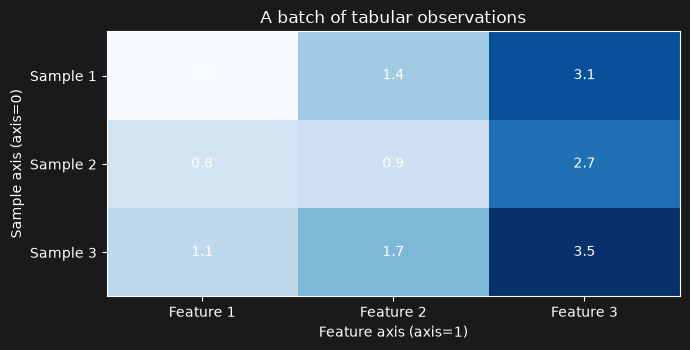

In [5]:
feature_matrix = np.array(
    [[0.2, 1.4, 3.1], [0.8, 0.9, 2.7], [1.1, 1.7, 3.5]],
    dtype=np.float32,
)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.imshow(feature_matrix, cmap="Blues", aspect="auto")
for i in range(feature_matrix.shape[0]):
    for j in range(feature_matrix.shape[1]):
        ax.text(j, i, f"{feature_matrix[i, j]:.1f}", ha="center", va="center")
ax.set_xticks(range(3), ["Feature 1", "Feature 2", "Feature 3"])
ax.set_yticks(range(3), ["Sample 1", "Sample 2", "Sample 3"])
ax.set_title("A batch of tabular observations")
ax.set_xlabel("Feature axis (axis=1)")
ax.set_ylabel("Sample axis (axis=0)")
plt.tight_layout()
plt.show()

---
# 3. Creating and Manipulating Tensors

## 3.1 Creating Tensors

TensorFlow provides several functions for creating tensors, including `tf.constant`, `tf.zeros`, `tf.ones`, `tf.fill`, `tf.range`, and random-number generators.

In [6]:
zeros = tf.zeros((2, 3))
ones = tf.ones((2, 3), dtype=tf.float32)
filled = tf.fill((2, 2), 5.0)
sequence = tf.range(start=0, limit=10, delta=2)
random_tensor = tf.random.normal(shape=(2, 3), mean=0.0, stddev=1.0, seed=SEED)

print("Zeros:\n", zeros.numpy())
print("\nOnes:\n", ones.numpy())
print("\nFilled:\n", filled.numpy())
print("\nSequence:", sequence.numpy())
print("\nRandom tensor:\n", random_tensor.numpy())

Zeros:
 [[0. 0. 0.]
 [0. 0. 0.]]

Ones:
 [[1. 1. 1.]
 [1. 1. 1.]]

Filled:
 [[5. 5.]
 [5. 5.]]

Sequence: [0 2 4 6 8]

Random tensor:
 [[ 1.3148774  -0.15421568  0.9113878 ]
 [-0.7991441  -0.10875293  0.28436786]]


## 3.2 TensorFlow Constants and Variables

A `tf.Tensor` is immutable: its stored value cannot be changed in place. A `tf.Variable` is a mutable tensor-like object designed to hold state, such as trainable model weights.

For example, a trainable parameter $w$ can be updated during optimization:

$$
w_{t+1} = w_t - \eta \frac{\partial L}{\partial w_t}
$$

where $\eta$ is the learning rate and $L$ is the loss.

In [7]:
constant_value = tf.constant([0.2, 0.8], dtype=tf.float32)
trainable_weights = tf.Variable([0.2, 0.8], dtype=tf.float32, name="example_weights")

print("Constant:", constant_value.numpy())
print("Variable before update:", trainable_weights.numpy())

trainable_weights.assign([0.3, 0.7])
trainable_weights.assign_add([0.1, -0.1])

print("Variable after updates:", trainable_weights.numpy())

Constant: [0.2 0.8]
Variable before update: [0.2 0.8]
Variable after updates: [0.4        0.59999996]


## 3.3 Indexing and Slicing

TensorFlow supports familiar indexing and slicing patterns. As with NumPy, the first index selects along axis 0, the second along axis 1, and so on.

In [8]:
values = tf.constant(
    [[10, 20, 30], [40, 50, 60], [70, 80, 90]],
    dtype=tf.int32,
)

print("First row:", values[0].numpy())
print("Second column:", values[:, 1].numpy())
print("Top-left 2 x 2 block:\n", values[:2, :2].numpy())
print("Last element:", values[-1, -1].numpy())

First row: [10 20 30]
Second column: [20 50 80]
Top-left 2 x 2 block:
 [[10 20]
 [40 50]]
Last element: 90


## 3.4 Reshaping and Transposing

Reshaping changes how elements are arranged without changing their order or total number. If a tensor has $n$ elements, its new shape must also contain $n$ elements.

$$
\operatorname{size}(X) = \operatorname{size}(\operatorname{reshape}(X))
$$

Transposition changes the order of axes. For a matrix, it exchanges rows and columns.

In [9]:
original = tf.range(12)
reshaped = tf.reshape(original, shape=(3, 4))
transposed = tf.transpose(reshaped)
flattened = tf.reshape(reshaped, shape=(-1,))

print("Original:", original.numpy(), "shape:", original.shape)
print("\nReshaped:\n", reshaped.numpy(), "shape:", reshaped.shape)
print("\nTransposed:\n", transposed.numpy(), "shape:", transposed.shape)
print("\nFlattened:", flattened.numpy(), "shape:", flattened.shape)

Original: [ 0  1  2  3  4  5  6  7  8  9 10 11] shape: (12,)

Reshaped:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] shape: (3, 4)

Transposed:
 [[ 0  4  8]
 [ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]] shape: (4, 3)

Flattened: [ 0  1  2  3  4  5  6  7  8  9 10 11] shape: (12,)


## 3.5 Broadcasting

**Broadcasting** allows TensorFlow to perform element-wise operations on tensors with compatible shapes without manually repeating values.

Starting from the rightmost dimensions, two dimensions are compatible when they are equal or when at least one of them is `1`.

For example, a matrix with shape `(3, 2)` can be combined with a vector of shape `(2,)`:

$$
\begin{bmatrix}a & b\\c & d\\e & f\end{bmatrix}
+
\begin{bmatrix}u & v\end{bmatrix}
=
\begin{bmatrix}a+u & b+v\\c+u & d+v\\e+u & f+v\end{bmatrix}
$$

In [10]:
measurements = tf.constant([[10.0, 20.0], [12.0, 18.0], [14.0, 22.0]])
feature_offsets = tf.constant([1.0, 2.0])

adjusted = measurements + feature_offsets
print("Measurements shape:", measurements.shape)
print("Offsets shape:", feature_offsets.shape)
print("Broadcast result:\n", adjusted.numpy())

Measurements shape: (3, 2)
Offsets shape: (2,)
Broadcast result:
 [[11. 22.]
 [13. 20.]
 [15. 24.]]


## 3.6 Reductions and Axes

A **reduction** combines values along one or more axes. For a matrix where rows are samples and columns are features:

- `axis=0` reduces across samples and returns one value per feature.
- `axis=1` reduces across features and returns one value per sample.
- `axis=None` reduces all elements to one scalar.

In [11]:
observations = tf.constant([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])

print("Column sums (axis=0):", tf.reduce_sum(observations, axis=0).numpy())
print("Row sums (axis=1):", tf.reduce_sum(observations, axis=1).numpy())
print("Global mean:", tf.reduce_mean(observations).numpy())
print("Column means (axis=0):", tf.reduce_mean(observations, axis=0).numpy())

Column sums (axis=0): [5. 7. 9.]
Row sums (axis=1): [ 6. 15.]
Global mean: 3.5
Column means (axis=0): [2.5 3.5 4.5]


## 3.7 Common Mathematical Operations

TensorFlow offers element-wise operations, matrix multiplication, and linear-algebra functions. Distinguish element-wise multiplication (`*`) from matrix multiplication (`tf.matmul` or `@`).

In [12]:
A = tf.constant([[1.0, 2.0], [3.0, 4.0]])
B = tf.constant([[5.0, 6.0], [7.0, 8.0]])

print("Element-wise multiplication:\n", (A * B).numpy())
print("\nMatrix multiplication:\n", tf.matmul(A, B).numpy())
print("\nMatrix product using @:\n", (A @ B).numpy())
print("\nElement-wise square:\n", tf.square(A).numpy())

Element-wise multiplication:
 [[ 5. 12.]
 [21. 32.]]

Matrix multiplication:
 [[19. 22.]
 [43. 50.]]

Matrix product using @:
 [[19. 22.]
 [43. 50.]]

Element-wise square:
 [[ 1.  4.]
 [ 9. 16.]]


## 3.8 NumPy and TensorFlow Interoperability

TensorFlow works naturally with NumPy. NumPy arrays can be converted into tensors, and eager tensors can be converted into NumPy arrays with `.numpy()`.

Be aware that `.numpy()` transfers tensor values to the host (CPU) and is generally used for inspection, plotting, or integration with non-TensorFlow tools—not inside a graph-compiled computation.

In [13]:
numpy_features = np.array([[0.1, 0.2], [0.3, 0.4]], dtype=np.float32)
tensor_features = tf.convert_to_tensor(numpy_features)
returned_array = tensor_features.numpy()

print("Original NumPy type:", type(numpy_features))
print("TensorFlow type:", type(tensor_features))
print("Back to NumPy type:", type(returned_array))
print("Values preserved:", np.allclose(numpy_features, returned_array))

Original NumPy type: <class 'numpy.ndarray'>
TensorFlow type: <class 'tensorflow.python.framework.ops.EagerTensor'>
Back to NumPy type: <class 'numpy.ndarray'>
Values preserved: True


### Knowledge Check: Predict the Shapes

Before running the next cell, predict the shapes of `a + b`, `tf.reshape(a, (2, 3))`, and `tf.reduce_sum(a, axis=0)`. Then use the outputs to check your reasoning.

In [14]:
a = tf.ones((2, 3))
b = tf.constant([1.0, 2.0, 3.0])

print("a shape:", a.shape)
print("b shape:", b.shape)
print("a + b shape:", (a + b).shape)
print("reshape shape:", tf.reshape(a, (2, 3)).shape)
print("sum over axis 0 shape:", tf.reduce_sum(a, axis=0).shape)

a shape: (2, 3)
b shape: (3,)
a + b shape: (2, 3)
reshape shape: (2, 3)
sum over axis 0 shape: (3,)


---
# 4. Automatic Differentiation with `tf.GradientTape`

## 4.1 Why Automatic Differentiation?

Training a neural network requires derivatives of a loss function with respect to model parameters. Manually deriving every gradient is impractical for large computational graphs.

TensorFlow records operations executed inside a `tf.GradientTape` context and uses that recorded computation to calculate derivatives with the chain rule.

For a scalar function $y=f(x)$, the tape can calculate:

$$
\frac{dy}{dx}
$$

For a loss $L$ that depends on many parameters, it can calculate a gradient for each parameter:

$$
\nabla_{\theta} L = \left[\frac{\partial L}{\partial \theta_1},\ldots,\frac{\partial L}{\partial \theta_p}\right]
$$

In [15]:
x = tf.Variable(3.0)

with tf.GradientTape() as tape:
    y = x**2 + 2.0 * x + 1.0

dy_dx = tape.gradient(y, x)

print("x:", x.numpy())
print("y:", y.numpy())
print("dy/dx:", dy_dx.numpy())
print("Expected derivative 2x + 2:", (2.0 * x + 2.0).numpy())

x: 3.0
y: 16.0
dy/dx: 8.0
Expected derivative 2x + 2: 8.0


## 4.2 Gradients of Vector-Valued Expressions

When a scalar objective depends on a vector, TensorFlow calculates the gradient with respect to every element. For example, if

$$
L(\mathbf{x}) = \sum_{i=1}^{n}x_i^2,
$$

then

$$
\nabla_{\mathbf{x}}L = 2\mathbf{x}.
$$

In [16]:
x_vector = tf.Variable([1.0, 2.0, 3.0])

with tf.GradientTape() as tape:
    loss_value = tf.reduce_sum(tf.square(x_vector))

vector_gradient = tape.gradient(loss_value, x_vector)

print("Input vector:", x_vector.numpy())
print("Loss:", loss_value.numpy())
print("Gradient:", vector_gradient.numpy())
print("Expected gradient:", (2.0 * x_vector).numpy())

Input vector: [1. 2. 3.]
Loss: 14.0
Gradient: [2. 4. 6.]
Expected gradient: [2. 4. 6.]


## 4.3 Gradients with Respect to Multiple Variables

A neural-network layer contains multiple trainable parameters. Pass a list of variables to `tape.gradient` to obtain their gradients in the same order.

In [17]:
weight = tf.Variable(2.0)
bias = tf.Variable(1.0)
input_value = tf.constant(3.0)
target_value = tf.constant(10.0)

with tf.GradientTape() as tape:
    prediction = weight * input_value + bias
    loss = tf.square(prediction - target_value)

weight_gradient, bias_gradient = tape.gradient(loss, [weight, bias])

print("Prediction:", prediction.numpy())
print("Loss:", loss.numpy())
print("dLoss/dWeight:", weight_gradient.numpy())
print("dLoss/dBias:", bias_gradient.numpy())

Prediction: 7.0
Loss: 9.0
dLoss/dWeight: -18.0
dLoss/dBias: -6.0


## 4.4 Watching Tensors Explicitly

By default, `GradientTape` automatically watches trainable `tf.Variable` objects. A constant tensor is not automatically watched. Use `tape.watch()` when you need a derivative with respect to a non-variable tensor.

In [18]:
constant_input = tf.constant(4.0)

with tf.GradientTape() as tape:
    tape.watch(constant_input)
    output = constant_input**3

constant_gradient = tape.gradient(output, constant_input)
print("d(x^3)/dx at x=4:", constant_gradient.numpy())

d(x^3)/dx at x=4: 48.0


## 4.5 A Single Gradient-Descent Update

The following example performs one parameter update for a simple linear model. It connects automatic differentiation to the gradient-descent rule introduced in Notebook 02.

$$
\theta_{t+1}=\theta_t-\eta\nabla_{\theta}L(\theta_t)
$$

In [19]:
parameter = tf.Variable(0.0)
learning_rate = 0.1

def objective(value):
    return tf.square(value - 5.0)

with tf.GradientTape() as tape:
    current_loss = objective(parameter)

gradient = tape.gradient(current_loss, parameter)
parameter.assign_sub(learning_rate * gradient)

print("Gradient:", gradient.numpy())
print("Updated parameter:", parameter.numpy())
print("Loss after one update:", objective(parameter).numpy())

Gradient: -10.0
Updated parameter: 1.0
Loss after one update: 16.0


## 4.6 Visualizing a Differentiable Function and Its Gradient

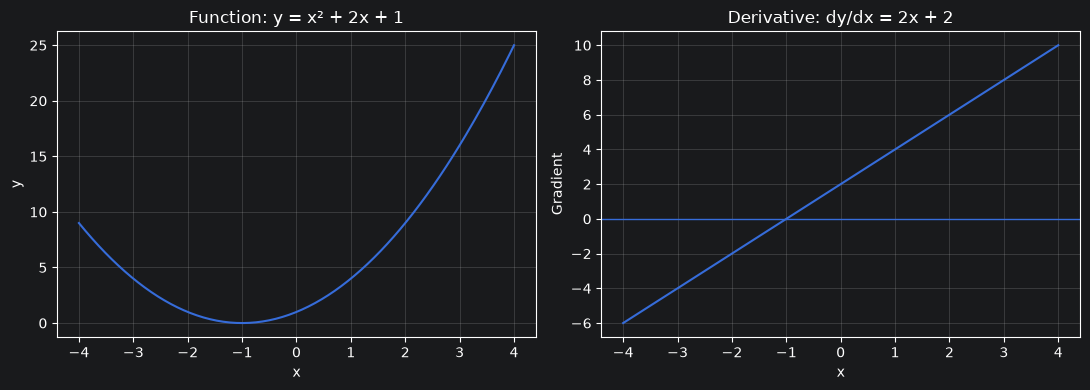

In [20]:
x_values = np.linspace(-4, 4, 200, dtype=np.float32)
y_values = x_values**2 + 2 * x_values + 1

tf_x = tf.constant(x_values)
with tf.GradientTape() as tape:
    tape.watch(tf_x)
    tf_y = tf_x**2 + 2.0 * tf_x + 1.0
tf_grad = tape.gradient(tf_y, tf_x)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x_values, y_values)
axes[0].set_title("Function: y = x² + 2x + 1")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].grid(alpha=0.3)
axes[1].plot(x_values, tf_grad.numpy())
axes[1].axhline(0, linewidth=1)
axes[1].set_title("Derivative: dy/dx = 2x + 2")
axes[1].set_xlabel("x")
axes[1].set_ylabel("Gradient")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
# 5. Eager Execution and `tf.function`

## 5.1 Eager Execution

TensorFlow 2 executes operations eagerly by default. This means an operation runs immediately and its result can be inspected directly. Eager execution makes experimentation and debugging intuitive.

In [21]:
value = tf.constant([1.0, 2.0, 3.0])
result = tf.square(value) + 1.0

print("Result is available immediately:", result.numpy())

Result is available immediately: [ 2.  5. 10.]


## 5.2 Using `tf.function`

`tf.function` converts a Python function into a TensorFlow graph function. Graph execution can improve performance and portability for suitable workloads. It may introduce tracing overhead and constraints, so it is useful to understand the distinction rather than decorate every function automatically.

In [22]:
@tf.function

def square_plus_one(tensor):
    return tf.square(tensor) + 1.0

input_tensor = tf.constant([2.0, 3.0, 4.0])
print(square_plus_one(input_tensor).numpy())

[ 5. 10. 17.]


---
# 6. Prepare a Reproducible Example Dataset

## 6.1 Define a Small Synthetic Regression Problem

We generate three numerical features and a continuous target. The target depends on a linear combination of two features and a nonlinear transformation of the third feature, plus noise.

$$
y = 2.5x_1 - 1.2x_2 + 0.7x_3^2 + 0.4 + \epsilon
$$

where $\epsilon$ is random noise. This is a controlled teaching example, not a biological dataset and not evidence of a scientific relationship.

In [23]:
rng = np.random.default_rng(SEED)
N_SAMPLES = 1200
N_FEATURES = 3

X = rng.uniform(-2.0, 2.0, size=(N_SAMPLES, N_FEATURES)).astype(np.float32)
noise = rng.normal(0.0, 0.2, size=(N_SAMPLES, 1)).astype(np.float32)
y = (
    2.5 * X[:, [0]]
    - 1.2 * X[:, [1]]
    + 0.7 * np.square(X[:, [2]])
    + 0.4
    + noise
).astype(np.float32)

print("Feature matrix shape:", X.shape)
print("Target matrix shape:", y.shape)
print("Feature dtype:", X.dtype)
print("Target dtype:", y.dtype)

Feature matrix shape: (1200, 3)
Target matrix shape: (1200, 1)
Feature dtype: float32
Target dtype: float32


## 6.2 Inspect the Data

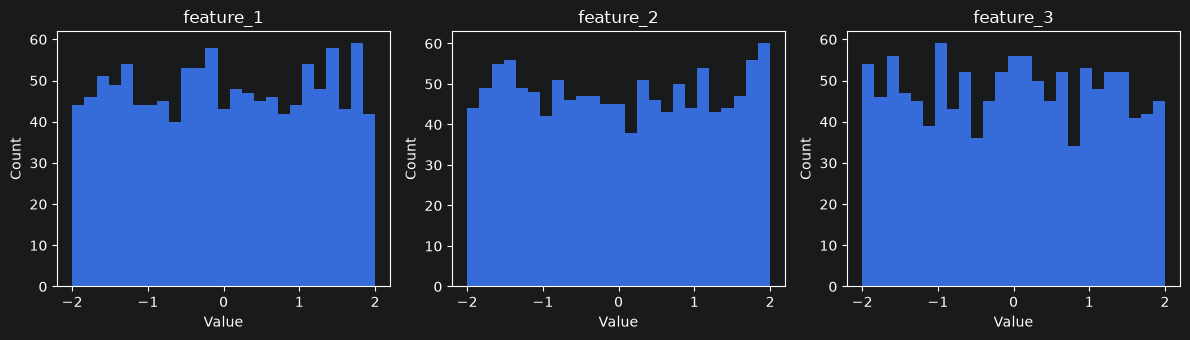

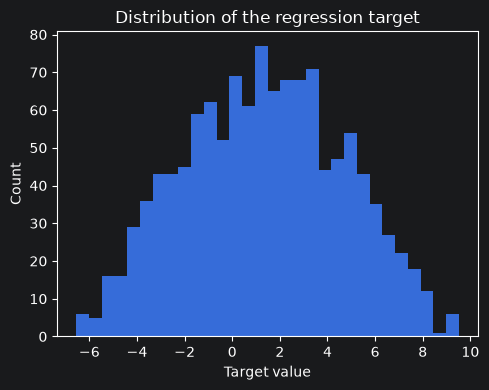

In [24]:
feature_names = ["feature_1", "feature_2", "feature_3"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for index, ax in enumerate(axes):
    ax.hist(X[:, index], bins=25)
    ax.set_title(feature_names[index])
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")
axes[0].set_ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
plt.hist(y[:, 0], bins=30)
plt.title("Distribution of the regression target")
plt.xlabel("Target value")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 6.3 Split Before Fitting Preprocessing Parameters

We divide the observations into training, validation, and test sets before estimating normalization parameters. This is important because information from validation or test data must not influence preprocessing fitted on the training data.

- **Training set:** used to estimate model parameters and preprocessing statistics.
- **Validation set:** used to monitor model performance and make model-development decisions.
- **Test set:** held back for final evaluation.

In [25]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (840, 3) (840, 1)
Validation: (180, 3) (180, 1)
Test: (180, 3) (180, 1)


## 6.4 Calculate Normalization Statistics from Training Data Only

For each feature, standardization applies:

$$
x_{\text{standardized}} = \frac{x-\mu_{\text{train}}}{\sigma_{\text{train}}}
$$

The training mean and standard deviation are reused for the validation and test sets. Do not calculate separate statistics for each split, because that would give the model different feature transformations at evaluation time.

In [26]:
feature_mean = X_train.mean(axis=0).astype(np.float32)
feature_std = X_train.std(axis=0).astype(np.float32)
feature_std = np.where(feature_std == 0.0, 1.0, feature_std).astype(np.float32)

X_train_scaled = ((X_train - feature_mean) / feature_std).astype(np.float32)
X_val_scaled = ((X_val - feature_mean) / feature_std).astype(np.float32)
X_test_scaled = ((X_test - feature_mean) / feature_std).astype(np.float32)

print("Training feature means after scaling:", X_train_scaled.mean(axis=0))
print("Training feature standard deviations:", X_train_scaled.std(axis=0))

Training feature means after scaling: [-6.7410016e-10  2.3699942e-08  1.6178404e-08]
Training feature standard deviations: [0.9999999 0.9999998 0.9999998]


---
# 7. Building Models with Keras

Keras provides three common ways to define models:

1. **Sequential API:** a simple stack of layers.
2. **Functional API:** a graph of layers that can support branching, shared layers, and multiple inputs or outputs.
3. **Model subclassing:** a Python class for more customized forward-pass logic.

Choose the simplest API that expresses the model you need. The Functional API is a strong default for many non-trivial architectures; subclassing is useful when the forward pass requires behavior that is difficult to express as a static graph.

## 7.1 Sequential API

Use `Sequential` when each layer feeds directly into the next layer in a single stack.

In [27]:
sequential_model = keras.Sequential(
    [
        keras.Input(shape=(N_FEATURES,), name="features"),
        layers.Dense(16, activation="relu", name="hidden_1"),
        layers.Dense(8, activation="relu", name="hidden_2"),
        layers.Dense(1, name="regression_output"),
    ],
    name="sequential_regressor",
)

sequential_model.summary()

Model: "sequential_regressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regression_output (Dense)       │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209 (836.00 B)

 Trainable params: 209 (836.00 B)

 Non-trainable params: 0 (0.00 B)

## 7.2 Functional API

The Functional API represents a model as a directed acyclic graph. The example below creates two parallel feature transformations and combines their outputs before the prediction layer.

In [28]:
inputs = keras.Input(shape=(N_FEATURES,), name="all_features")

branch_a = layers.Dense(12, activation="relu", name="relu_branch")(inputs)
branch_b = layers.Dense(8, activation="tanh", name="tanh_branch")(inputs)
merged = layers.Concatenate(name="merge_branches")([branch_a, branch_b])
merged = layers.Dense(8, activation="relu", name="shared_representation")(merged)
outputs = layers.Dense(1, name="prediction")(merged)

functional_model = keras.Model(inputs=inputs, outputs=outputs, name="functional_regressor")
functional_model.summary()

Model: "functional_regressor"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ all_features        │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu_branch (Dense) │ (None, 12)        │         48 │ all_features[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tanh_branch (Dense) │ (None, 8)         │         32 │ all_features[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ merge_branches      │ (None, 20)        │          0 │ relu_branch[0][0… │
│ (Concatenate)       │                   │            │ tanh_branch[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_representat… │ (None, 8)         │        168 │ merge_branches[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prediction (Dense)  │ (None, 1)         │          9 │ shared_represent… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 257 (1.00 KB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 0 (0.00 B)

## 7.3 Model Subclassing

Subclassing allows you to define a model as a Python class. The `call()` method describes the forward pass. Subclassed models are flexible, but their structure is less directly inspectable than a Functional model until they are built by calling them.

In [29]:
class SubclassedRegressor(keras.Model):
    def __init__(self, units=16, **kwargs):
        super().__init__(**kwargs)
        self.hidden_layer = layers.Dense(units, activation="relu")
        self.output_layer = layers.Dense(1)

    def call(self, inputs, training=False):
        x = self.hidden_layer(inputs)
        return self.output_layer(x)


subclassed_model = SubclassedRegressor(units=16, name="subclassed_regressor")
subclassed_example_output = subclassed_model(tf.zeros((1, N_FEATURES)))

print("Output shape:", subclassed_example_output.shape)
subclassed_model.summary()

Output shape: (1, 1)


Model: "subclassed_regressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (1, 16)                │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 1)                 │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

## 7.4 Comparing the Three Keras Model-Construction Approaches

| API | Best suited for | Main strength | Main limitation |
|---|---|---|---|
| Sequential | A simple layer stack | Minimal code and easy inspection | Does not express arbitrary branching or multi-input graphs |
| Functional | Most graph-like architectures | Flexible topology and inspectable graph | Not designed for every dynamic control-flow pattern |
| Subclassing | Custom forward-pass behavior | Maximum Python-level flexibility | More responsibility for building, inspection, and serialization details |

All three approaches use Keras layers and can generally be trained with `compile()` and `fit()`.

---
# 8. Building Input Pipelines with `tf.data`

## 8.1 Why Use `tf.data`?

A data pipeline prepares examples and supplies batches to the model. A good pipeline can shuffle training examples, apply preprocessing, batch observations, cache reusable work, and prefetch batches.

A typical conceptual workflow is:

$$
\text{Source} \rightarrow \text{Shuffle} \rightarrow \text{Map} \rightarrow \text{Batch} \rightarrow \text{Prefetch}
$$

The best ordering depends on the transformation and memory constraints. For example, caching before shuffling allows a fresh shuffle order on each iteration; caching after a shuffle can preserve the first shuffled order.

## 8.2 Create a Dataset from NumPy Arrays

`tf.data.Dataset.from_tensor_slices()` creates a dataset in which each element is one aligned observation (or one tuple of observation and target).

In [30]:
raw_train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))
raw_validation_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val))

print("Dataset element specification:")
print(raw_train_dataset.element_spec)
print("\nOne example:")
for example_features, example_target in raw_train_dataset.take(1):
    print("Features:", example_features.numpy())
    print("Target:", example_target.numpy())

Dataset element specification:
(TensorSpec(shape=(3,), dtype=tf.float32, name=None), TensorSpec(shape=(1,), dtype=tf.float32, name=None))

One example:
Features: [-1.675384   -1.9367778  -0.09119747]
Target: [-1.5971425]


## 8.3 Apply Preprocessing with `map()`

A mapping function receives one dataset element and returns the transformed element. Here, each feature vector is standardized using the training-set mean and standard deviation calculated earlier.

In [31]:
mean_tensor = tf.constant(feature_mean, dtype=tf.float32)
std_tensor = tf.constant(feature_std, dtype=tf.float32)


def normalize_example(features, target):
    normalized_features = (features - mean_tensor) / std_tensor
    return normalized_features, target

normalized_train_dataset = raw_train_dataset.map(
    normalize_example,
    num_parallel_calls=tf.data.AUTOTUNE,
)

for normalized_features, target in normalized_train_dataset.take(1):
    print("Normalized features:", normalized_features.numpy())
    print("Target:", target.numpy())

Normalized features: [-1.4560739  -1.6264918  -0.07996148]
Target: [-1.5971425]


## 8.4 Shuffle and Batch

- `shuffle(buffer_size)` uses a buffer to randomize element order. A buffer as large as the dataset provides a full shuffle, at the cost of memory.
- `batch(batch_size)` groups individual examples into batches.
- `drop_remainder=False` (the default) keeps the final smaller batch when the dataset size is not divisible by the batch size.

In [32]:
BATCH_SIZE = 32

shuffled_batched_dataset = (
    normalized_train_dataset
    .shuffle(
        buffer_size=len(X_train),
        seed=SEED,
        reshuffle_each_iteration=True,
    )
    .batch(BATCH_SIZE)
)

for batch_features, batch_targets in shuffled_batched_dataset.take(1):
    print("Batch feature shape:", batch_features.shape)
    print("Batch target shape:", batch_targets.shape)

Batch feature shape: (32, 3)
Batch target shape: (32, 1)


## 8.5 Cache and Prefetch

- `cache()` stores the elements produced upstream so that expensive upstream operations do not need to run again in every epoch. It can use memory or a file path.
- `prefetch(tf.data.AUTOTUNE)` overlaps input preparation with model execution and lets TensorFlow tune the prefetch buffer.
- `map(..., num_parallel_calls=tf.data.AUTOTUNE)` can parallelize element transformations.

Caching consumes storage or memory, so it should only be used when the cached dataset fits the available resources. Prefetching is often a useful final pipeline step.

In [33]:
def make_training_dataset(features, targets, batch_size=BATCH_SIZE):
    dataset = tf.data.Dataset.from_tensor_slices((features, targets))
    dataset = dataset.cache()
    dataset = dataset.shuffle(
        buffer_size=len(features),
        seed=SEED,
        reshuffle_each_iteration=True,
    )
    dataset = dataset.map(
        normalize_example,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


def make_evaluation_dataset(features, targets, batch_size=BATCH_SIZE):
    dataset = tf.data.Dataset.from_tensor_slices((features, targets))
    dataset = dataset.map(
        normalize_example,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_dataset = make_training_dataset(X_train, y_train)
validation_dataset = make_evaluation_dataset(X_val, y_val)
test_dataset = make_evaluation_dataset(X_test, y_test)

print("Training dataset spec:", train_dataset.element_spec)
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Training dataset spec: (TensorSpec(shape=(None, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
Validation batches: 6
Test batches: 6


## 8.6 Inspect a Batch from the Final Pipeline

In [34]:
for batch_features, batch_targets in train_dataset.take(1):
    print("Feature batch shape:", batch_features.shape)
    print("Target batch shape:", batch_targets.shape)
    print("Feature batch mean (approximately):", tf.reduce_mean(batch_features, axis=0).numpy())

Feature batch shape: (32, 3)
Target batch shape: (32, 1)
Feature batch mean (approximately): [ 0.00559133 -0.46931365 -0.1789701 ]


---
# 9. Train and Evaluate a Model with the Input Pipeline

## 9.1 Define the Model

We use a compact Sequential model for the end-to-end example. The model receives three standardized features and returns one continuous prediction.

In [35]:
tf.keras.utils.set_random_seed(SEED)

model = keras.Sequential(
    [
        keras.Input(shape=(N_FEATURES,), name="features"),
        layers.Dense(32, activation="relu", name="hidden_1"),
        layers.Dense(16, activation="relu", name="hidden_2"),
        layers.Dense(1, name="regression_output"),
    ],
    name="tfdata_regressor",
)

model.summary()

Model: "tfdata_regressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ regression_output (Dense)       │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673 (2.63 KB)

 Trainable params: 673 (2.63 KB)

 Non-trainable params: 0 (0.00 B)

## 9.2 Compile the Model

`compile()` specifies how the model is optimized and which metrics are reported. Mean squared error is used as the loss, while mean absolute error is reported as an additional metric.

In [36]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mean_squared_error",
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)

print("Model compiled successfully.")

Model compiled successfully.


## 9.3 Train with `fit()`

Keras can consume a `tf.data.Dataset` directly. `EarlyStopping` monitors validation loss and restores the weights from the best epoch if training stops early.

In [37]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=40,
    callbacks=[early_stopping],
    verbose=0,
)

print("Epochs completed:", len(history.history["loss"]))
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epochs completed: 40
Final training loss: 0.07286112010478973
Final validation loss: 0.06887228041887283


## 9.4 Visualize the Training History

Training curves help identify optimization behavior and possible overfitting. A lower training loss does not automatically mean that a model generalizes well; compare it with validation performance.

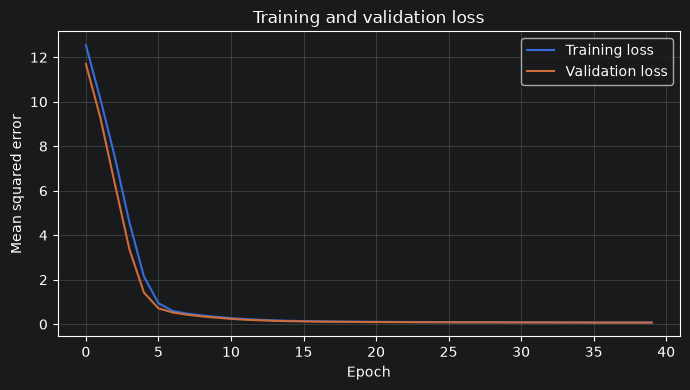

In [38]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history.history["loss"], label="Training loss")
ax.plot(history.history["val_loss"], label="Validation loss")
ax.set_title("Training and validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9.5 Evaluate on the Held-Out Test Set

Use the test set after model-development decisions are complete. It provides an estimate of performance on observations that were not used for fitting or validation-based choices.

In [39]:
test_results = model.evaluate(test_dataset, return_dict=True, verbose=0)

for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")

loss: 0.0704
mae: 0.2055


## 9.6 Inspect Predictions

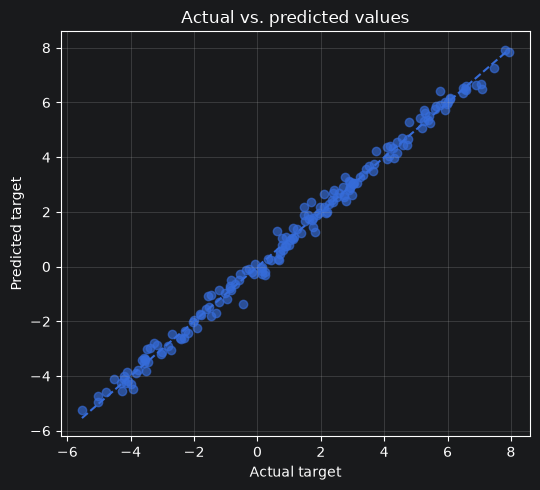

Test MAE (computed with NumPy): 0.20554598


In [40]:
predictions = model.predict(test_dataset, verbose=0).reshape(-1)
actual_values = y_test.reshape(-1)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(actual_values, predictions, alpha=0.65)
minimum = min(actual_values.min(), predictions.min())
maximum = max(actual_values.max(), predictions.max())
ax.plot([minimum, maximum], [minimum, maximum], linestyle="--")
ax.set_title("Actual vs. predicted values")
ax.set_xlabel("Actual target")
ax.set_ylabel("Predicted target")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Test MAE (computed with NumPy):", np.mean(np.abs(actual_values - predictions)))

## 9.7 Save and Reload the Model

The recommended native Keras format uses the `.keras` extension. The following cell saves the model in the notebook's working directory. Uncomment the reload lines to verify that the saved model can be loaded again.

In [41]:
model_path = "notebook03_regression_model.keras"
model.save(model_path)
print("Model saved to:", model_path)

# Reload the model when needed:
# reloaded_model = keras.models.load_model(model_path)
# print(reloaded_model.evaluate(test_dataset, return_dict=True, verbose=0))

Model saved to: notebook03_regression_model.keras


---
# 10. Common TensorFlow and Data-Pipeline Mistakes

| Mistake | Why it is a problem | Better practice |
|---|---|---|
| Mixing `float32` and `int32` in arithmetic | TensorFlow operations often require compatible dtypes | Cast deliberately with `tf.cast()` or create tensors with the intended dtype |
| Confusing rank and shape | A tensor's rank is the number of axes; shape gives each axis size | Inspect both `tensor.ndim`/`tf.rank()` and `tensor.shape` |
| Using `*` when matrix multiplication is intended | `*` performs element-wise multiplication | Use `tf.matmul(A, B)` or `A @ B` |
| Normalizing before splitting the data | Validation/test information can leak into preprocessing | Split first; fit preprocessing on training data only |
| Shuffling validation or test data unnecessarily | It can make ordered inspection harder and complicate reproducibility | Shuffle training data; keep evaluation pipelines deterministic unless order is irrelevant |
| Caching after a shuffle unintentionally | The cached order may repeat across epochs | Cache before shuffle when each epoch should reshuffle |
| Omitting `prefetch()` | Data preparation may leave the accelerator or CPU waiting | Consider `prefetch(tf.data.AUTOTUNE)` as the final pipeline step |
| Calling `.numpy()` inside graph-only code | `.numpy()` is an eager-mode host conversion | Keep tensor operations inside TensorFlow computations |
| Expecting `GradientTape` to watch constants automatically | Non-variable tensors are not watched by default | Call `tape.watch(tensor)` explicitly |

## 10.1 Shape-Debugging Checklist

When a model reports a shape error, inspect the following:

1. Is the input a single observation or a batch?
2. Does the feature dimension match the model's input shape?
3. Does the target shape match the model output shape?
4. Are the data types compatible with the layer operations?
5. Did a reshape or transpose change the intended axis order?

---
# 11. Exercises

Try to complete these exercises before checking the hints. Use small tensors first and print shapes at every step.

## Exercise 1 — Tensor Inspection

Create a tensor with shape `(4, 3, 2)`. Print its rank, shape, data type, and total number of elements.

**Hint:** use `tf.reshape(tf.range(...), ...)`.

## Exercise 2 — Axis Operations

Create a matrix with shape `(5, 4)`. Calculate the sum across rows, the sum across columns, and the global mean. Write down the shape of each result before executing the code.

**Hint:** use `tf.reduce_sum()` and `tf.reduce_mean()` with different `axis` arguments.

## Exercise 3 — Broadcasting

Create a matrix of shape `(6, 3)` and a vector of shape `(3,)`. Add them. Then try to add a vector of shape `(4,)` and explain why the second operation is invalid.

**Hint:** compare dimensions from right to left.

## Exercise 4 — Automatic Differentiation

Use `tf.GradientTape` to calculate the derivative of:

$$
f(x)=3x^3-2x^2+4x-1
$$

at $x=2$. Verify the result using the analytical derivative:

$$
f'(x)=9x^2-4x+4
$$

## Exercise 5 — Build a Keras Model

Build a regression model with:

- An input with four features.
- Two hidden Dense layers with 32 and 16 units.
- ReLU activations in the hidden layers.
- One linear output unit.

Print the model summary and total parameter count.

## Exercise 6 — Build a `tf.data` Pipeline

Create a dataset from NumPy feature and target arrays. Shuffle it, batch it with a batch size of 16, and prefetch using `tf.data.AUTOTUNE`. Print the shapes of one batch.

## Exercise 7 — Prevent Data Leakage

Explain why the mean and standard deviation used to normalize validation and test data must be estimated from training data only. Write a short code example that follows this rule.

## Exercise 8 — Compare Model APIs

Describe a problem structure for which the Functional API is more convenient than Sequential. Then describe a situation where model subclassing may be justified.

## Optional Challenge — One Custom Training Step

Build a small Keras model and write one training step using `tf.GradientTape` and an optimizer's `apply_gradients()` method. Compare the update with the high-level `model.fit()` workflow.

A minimal pattern is:

```python
with tf.GradientTape() as tape:
    predictions = model(batch_features, training=True)
    loss_value = loss_function(batch_targets, predictions)

gradients = tape.gradient(loss_value, model.trainable_variables)
optimizer.apply_gradients(zip(gradients, model.trainable_variables))
```

This pattern will be explored more systematically when custom training loops and optimization are covered later in the learning path.

---
# 12. Key Takeaways

- TensorFlow tensors are multidimensional numerical objects described by rank, shape, and data type.
- Shape reasoning is essential: every operation and model layer expects compatible dimensions.
- Broadcasting supports compatible element-wise operations, while matrix multiplication uses linear-algebra rules.
- `tf.Variable` stores mutable state and is commonly used for trainable parameters.
- `tf.GradientTape` records operations and calculates derivatives through automatic differentiation.
- Keras provides Sequential, Functional, and subclassing approaches for model construction.
- `tf.data` provides composable pipelines for loading, transforming, batching, and prefetching data.
- Preprocessing parameters must be fitted on the training split and reused for validation and test data.
- A clean workflow separates training, validation, and final test evaluation.

## Connection to the Next Notebook

Notebook 04 will use these TensorFlow and Keras foundations to study artificial neural networks and regression in more depth, including model architecture, loss functions, optimization, and regression diagnostics.

---
# 13. References and Further Reading

1. TensorFlow — Tensor guide: https://www.tensorflow.org/guide/tensor
2. TensorFlow — Introduction to gradients and automatic differentiation: https://www.tensorflow.org/guide/autodiff
3. TensorFlow API — `tf.GradientTape`: https://www.tensorflow.org/api_docs/python/tf/GradientTape
4. TensorFlow — Better performance with the `tf.data` API: https://www.tensorflow.org/guide/data_performance
5. TensorFlow — `tf.data` guide: https://www.tensorflow.org/guide/data
6. Keras — Models API overview: https://keras.io/api/models/
7. Keras — Functional API guide: https://keras.io/guides/functional_api/
8. TensorFlow — Install with pip: https://www.tensorflow.org/install/pip

**Documentation note:** TensorFlow and Keras APIs evolve. Consult the official documentation linked above when adapting this notebook to a different library version or environment.

---

**End of Notebook 03 — TensorFlow, Keras, and Data Pipelines**